<a href="https://colab.research.google.com/github/MihaiDogariu/CV3/blob/main/laborator/CV_3_Lab_5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Image retrieval cu ResNet-18
Acest proiect construieste un sistem de **cautare de imagini dupa continut** (*content-based image retrieval*): pentru o imagine-interogare (*query*), sistemul intoarce cele mai asemanatoare imagini dintr-o baza de date (*galerie*). Asemanarea nu se calculeaza la nivel de pixeli, ci pe baza vectorilor de trasaturi (embeddings) produsi de o retea neuronala convolutionala. Calitatea procesului depinde de calitatea extractorului de trasaturi, iar acesta este scopul laboratorului: compararea mai multor moduri de a obtine un extractor bun si observarea efectului fiecaruia direct in rezultatele cautarii.

In acest sens, vom utiliza baza de date: **STL-10** si vom implementa arhitectura **ResNet-18**, strat cu strat.

Concepte acoperite:
1. Separarea extragerii de trasaturi de clasificare: reteaua include cele 2 componente, care pentru forward propagation actioneaza in cascada. Pentru retrieval se foloseste doar extragerea de trasaturi.
2. Antrenare de la 0 vs. pre-antrenare + finetune: comparatie intre o retea antrenata doar pe cele 5.000 de imagini etichetate si una care porneste de la ponderi invatate pe ImageNet (1,28 milioane de imagini).
3. Mecanism de atentie pe canale (Squeeze-and-Excitation): integrare in blocurile ResNet.

## 0. Configurare
Toti hiperparametrii care influenteaza durata rularii sunt adunati aici, ca sa poata fi modificati dintr-un singur loc. Hiperparametrii specifici fiecarui experiment (rata de invatare, de exemplu) sunt definiti langa experimentul respectiv, impreuna cu explicatia alegerii lor.

- `RETRAIN = False`: daca un model a fost deja antrenat si salvat in `./checkpoints`, este incarcat de pe disc. Setati `True` pentru a forta reantrenarea tuturor modelelor.
- `EPOCHS`: numarul de epoci pentru fiecare tip de antrenare. Antrenarea de la 0 are nevoie de mult mai multe epoci decat finetune-ul, pentru ca porneste de la ponderi aleatoare.
- `NUM_WORKERS`: cate procese pregatesc imaginile de antrenare in paralel (sectiunea 1.3). Setati 0 daca apar probleme la incarcarea datelor.

In [ ]:
import copy
import importlib.util
import math
import os
import random
import time

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
from sklearn.model_selection import train_test_split
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms
from tqdm import tqdm

# timm este folosit doar pentru a verifica arhitectura SE-ResNet-18 fata de o implementare de referinta
if importlib.util.find_spec('timm') is None:
    %pip install -q timm
import timm


# Alegem configuratia sistemului (cpu/gpu)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', device, '|', torch.cuda.get_device_name(0) if device.type == 'cuda' else '')


def set_seed(seed):
    # Fixam toate sursele de aleatorism, pentru ca experimentele sa fie comparabile intre ele
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


set_seed(0)

DATA_DIR = './data'
CKPT_DIR = './checkpoints'
os.makedirs(CKPT_DIR, exist_ok=True)

RETRAIN = False
BATCH_SIZE = 128
NUM_WORKERS = min(4, os.cpu_count())
EPOCHS = dict(scratch=60, linear_probe=10, finetune=20)

## 1. Baza de date STL-10

| Split | Imagini           | Observatii |
|---|-------------------|---|
| `train` | 5.000 (500/clasa) | split in `train` (4.500) + `val` (500) |
| `test` | 8.000 (800/clasa) | evaluarea clasificarii + interogari si galerie pentru retrieval |

Clase: `airplane, bird, car, cat, deer, dog, horse, monkey, ship, truck`. Toate imaginile sunt color, de 96x96 pixeli.

**Nota:** imaginile STL-10 provin din ImageNet. O retea pre-antrenata pe ImageNet a vazut, deci, imagini foarte asemanatoare (posibil chiar aceleasi) cu cele din setul STL-10. Avantajul pre-antrenarii ImageNet din sectiunea 5 este, prin urmare, subiectiv.

### 1.1 Descarcarea
`torchvision` descarca si dezarhiveaza baza de date, iar daca fisierele exista deja nu mai descarca nimic. Arhiva are 2,64 GB (aproximativ 5,3 GB pe disc dupa dezarhivare), deoarece contine si 100.000 de imagini neetichetate, pe care nu le folosim. Serverul Stanford nu raspunde intotdeauna: daca descarcarea esueaza, rulati din nou celula.

In [ ]:
datasets.STL10(root=DATA_DIR, split='train', download=True)

### 1.2 Incarcarea si impartirea datelor
`torchvision.datasets.STL10` ofera direct split-urile oficiale (`train`, `test`), deci mai avem de facut un singur lucru: sa impartim `train` in `train` + `val`.

`train_test_split` din scikit-learn pune deoparte 500 de imagini (10%) pentru selectia modelului (cea mai buna epoca). Cu `stratify`, fiecare clasa ramane cu exact 50 de imagini in `val`, deci acuratetea pe validare nu este influentata de o clasa mai bine reprezentata decat altele. `test` se foloseste doar la evaluarea finala, ca in laboratorul 4.

Deocamdata pastram doar **indicii**. Imaginile sunt selectate abia in sectiunea 1.3 (cu `Subset`), pentru ca `train` si `val` provin din acelasi fisier, dar au transformari diferite.

In [ ]:
# Imaginile etichetate, fara transformari: le folosim doar pentru indici si pentru calculul statisticilor (sectiunea 1.3)
labeled_set = datasets.STL10(root=DATA_DIR, split='train')
CLASSES = labeled_set.classes
NUM_CLASSES = len(CLASSES)

# Impartirea train -> train + val, stratificat: 50 de imagini din fiecare clasa merg in val
train_idx, valid_idx = train_test_split(np.arange(len(labeled_set)), test_size=500, stratify=labeled_set.labels, random_state=1)

print('Imagini pe clasa in val:', np.bincount(labeled_set.labels[valid_idx]))
print('Clase:', CLASSES)

### 1.3 Pre-procesare si augmentare
Folosim acelasi tipar ca in laboratorul 4: `Dataset` + `DataLoader` + `torchvision.transforms`.

- Normalizare cu media si deviatia standard calculate pe `train`, doar pe cele 4.500 de imagini de antrenare.
- Augmentare, doar la antrenare: padding de 12 pixeli prin reflexie + decupare aleatoare de 96x96 (translatii de pana la 12 pixeli) + oglindire orizontala cu probabilitate 0,5. Pe `val` si `test` nu augmentam: evaluarea trebuie sa fie determinista.
- `Subset` selecteaza dintr-un `Dataset` doar imaginile cu indicii din sectiunea 1.2. Cream doua obiecte `STL10` pentru split-ul `train`, pentru ca fiecare are propria transformare.
- `DataLoader` formeaza batch-urile. La antrenare, `num_workers` procese pregatesc imaginile in paralel, ca GPU-ul sa nu astepte dupa date, iar `persistent_workers=True` pastreaza aceste procese intre epoci, in loc sa le reporneasca. Pentru `val` si `test`, transformarile sunt atat de ieftine incat nu avem nevoie de procese auxiliare.

In [ ]:
# Statisticile se calculeaza doar pe imaginile de antrenare, separat pentru fiecare canal (R, G, B)
x_train = torch.from_numpy(labeled_set.data[train_idx])  # 4500 x 3 x 96 x 96, uint8
y_train = torch.from_numpy(labeled_set.labels[train_idx]).long()
std, mean = torch.std_mean(x_train.float() / 255, dim=(0, 2, 3))
MEAN, STD = mean.tolist(), std.tolist()
print('Normalizare calculata pe {} imagini: mean = {}, std = {}'.format(len(x_train), MEAN, STD))

normalize = transforms.Normalize(MEAN, STD)
augmentation = transforms.Compose([
    transforms.RandomCrop(96, padding=12, padding_mode='reflect'),
    transforms.RandomHorizontalFlip()])
train_transform = transforms.Compose([augmentation, transforms.ToTensor(), normalize])
eval_transform = transforms.Compose([transforms.ToTensor(), normalize])


train_dataset = Subset(datasets.STL10(root=DATA_DIR, split='train', transform=train_transform), train_idx)
valid_dataset = Subset(datasets.STL10(root=DATA_DIR, split='train', transform=eval_transform), valid_idx)
test_dataset = datasets.STL10(root=DATA_DIR, split='test', transform=eval_transform)

# Imaginile de test, neprelucrate, pentru vizualizari (sectiunea 7)
x_test = torch.from_numpy(test_dataset.data)             # 8000 x 3 x 96 x 96, uint8
y_test = torch.from_numpy(test_dataset.labels).long()

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS, persistent_workers=NUM_WORKERS > 0)
valid_loader = DataLoader(valid_dataset, batch_size=BATCH_SIZE)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE)

print('train: {}, val: {}, test: {}'.format(len(train_dataset), len(valid_dataset), len(test_dataset)))

In [ ]:
# Cate un exemplu din fiecare clasa (randul de sus) si aceleasi imagini dupa augmentare (randul de jos)
examples = [x_train[y_train == c][0] for c in range(NUM_CLASSES)]
fig, axes = plt.subplots(2, NUM_CLASSES, figsize=(2 * NUM_CLASSES, 4.4))
for row, images in enumerate([examples, [augmentation(img) for img in examples]]):
    for c in range(NUM_CLASSES):
        axes[row, c].imshow(images[c].permute(1, 2, 0).numpy())
        axes[row, c].axis('off')
        if row == 0:
            axes[row, c].set_title(CLASSES[c])
axes[0, 0].text(-10, 48, 'original', rotation=90, va='center', ha='right')
axes[1, 0].text(-10, 48, 'augmentat', rotation=90, va='center', ha='right')
plt.tight_layout()
plt.show()

## 2. Modelul: ResNet-18 si SE-ResNet-18

Resurse utile (documentatii si articole):
- strat convolutional: https://pytorch.org/docs/stable/generated/torch.nn.Conv2d.html
- normalizare pe batch: https://pytorch.org/docs/stable/generated/torch.nn.BatchNorm2d.html
- average pooling adaptiv: https://pytorch.org/docs/stable/generated/torch.nn.AdaptiveAvgPool2d.html
- ResNet: K. He et al., *Deep Residual Learning for Image Recognition*, CVPR 2016 (https://arxiv.org/abs/1512.03385)
- Squeeze-and-Excitation: J. Hu et al., *Squeeze-and-Excitation Networks*, CVPR 2018 (https://arxiv.org/abs/1709.01507)

ResNet-18 este una dintre cele mai folosite arhitecturi. Are ponderi pre-antrenate in `torchvision` si `timm`, iar o varianta cu SE se gaseste in `timm` (`legacy_seresnet18`).
- 11,2 milioane de parametri, deci se antreneaza in cateva minute pe imagini de 96x96, chiar si pe Colab. Pentru comparatie, VGG-16 are 138 de milioane.
- Are 4 stagii bine delimitate, fiecare cu rezolutie mai mica si mai multe canale decat precedentul.

### 2.1 Blocul rezidual
Un bloc `BasicBlock` calculeaza `y = ReLU(F(x) + x)`, unde `F` este succesiunea conv 3x3 -> BN -> ReLU -> conv 3x3 -> BN. Conexiunea directa (*skip connection*) are doua efecte:
- Gradientul circula direct prin suma `+ x` catre straturile anterioare, fara sa fie atenuat de fiecare strat intermediar. Asa se pot antrena retele foarte adanci fara problema disparitiei gradientului (vanishing gradient).
- Blocul invata doar o corectie `F(x)` fata de identitate. Daca un bloc nu este util, ii este usor sa invete `F(x) ≈ 0`.

Cand blocul reduce rezolutia (`stride=2`) sau schimba numarul de canale, `x` nu mai are aceeasi forma ca `F(x)`. In acest caz, ramura directa trece printr-o convolutie 1x1 cu acelasi stride (`downsample`).

### 2.2 Dimensiunile pentru intrari de 96x96

| Modul | Iesire | Pas fata de intrare (*stride*) |
|---|---|---|
| intrare | 3 x 96 x 96 | 1 |
| `conv1` 7x7/2 + `bn1` + ReLU | 64 x 48 x 48 | 2 |
| `maxpool` 3x3/2 | 64 x 24 x 24 | 4 |
| `layer1` (2 blocuri) | 64 x 24 x 24 | 4 |
| `layer2` (2 blocuri) | 128 x 12 x 12 | 8 |
| `layer3` (2 blocuri) | 256 x 6 x 6 | 16 |
| `layer4` (2 blocuri) | 512 x 3 x 3 | 32 |
| `avgpool` (global) | 512 | - |

Reteaua originala lucreaza pe 224x224 (iesire 512x7x7 la `layer4`). Pastram rezolutia nativa de 96x96: antrenarea este de aproximativ 5 ori mai rapida, cu pretul unei acurateti putin mai mici pentru modelul pre-antrenat, care a invatat obiecte la alta scara.

### 2.3 Separarea extragerii de trasaturi de clasificare
Clasa `ResNet18` are doua metode, iar `forward` le apeleaza in cascada:
- `extract_features` trece imaginea prin toate straturile pana la `avgpool` si intoarce un vector de 512 valori (embedding). Aceasta parte a retelei se numeste, de obicei, backbone;
- `classify` aplica stratul liniar `fc` (512 -> 10) peste vectorul de trasaturi. Acesta este capul de clasificare (head).

Separarea ne permite urmatoarele:
- pentru retrieval apelam doar `extract_features`. Galeria este reprezentata prin vectorii de trasaturi, iar cautarea inseamna gasirea vecinilor cei mai apropiati in spatiul de 512 dimensiuni. Stratul de clasificare nu intervine;
- putem ingheta backbone-ul si antrena doar stratul `fc` (linear probe), ca sa masuram cat de bune sunt trasaturile in sine.

### 2.4 Compatibilitatea cu torchvision
Modulele au exact aceleasi nume ca in `torchvision.models.resnet18` (`conv1`, `bn1`, `layer1.0.conv1`, `layer2.0.downsample.0`, `fc`...). Ponderile ImageNet se incarca deci direct cu `load_state_dict(strict=True)`. Daca arhitectura scrisa de noi ar diferi prin oricare strat, incarcarea ar esua cu o eroare care indica exact cheile diferite. Aceasta este o verificare foarte buna a implementarii (vezi sectiunea 2.6).

### 2.5 Squeeze-and-Excitation (SE)
O convolutie combina toate canalele de intrare cu aceeasi importanta pentru orice imagine. Blocul SE adauga un mecanism de atentie pe canale: in functie de continutul imaginii, intareste canalele utile si le atenueaza pe celelalte.
1. Squeeze: global average pooling pe fiecare canal, `C x H x W -> C`. Obtinem un descriptor global: "cat de prezenta este trasatura c in toata imaginea".
2. Excitation: `Linear(C, C/r) -> ReLU -> Linear(C/r, C) -> Sigmoid` produce o pondere in `(0, 1)` pentru fiecare canal. Gatul de sticla cu `r = 16` pastreaza un numar mic de parametri (`2C²/r` in loc de `C²`) si forteaza reteaua sa modeleze interdependentele dintre canale printr-o reprezentare compacta. Sigmoida (in loc de softmax) permite ca mai multe canale sa fie importante simultan.
3. **Scale:** fiecare canal al hartii de trasaturi este inmultit cu ponderea sa.

Blocul SE se plaseaza pe ramura reziduala, dupa `bn2` si inainte de suma cu `x` (ca in articolul original). SE recalibreaza doar corectia `F(x)`, iar calea identitate ramane neatinsa, deci proprietatea de propagare a gradientului se pastreaza.

In [ ]:
class SEBlock(nn.Module):
    def __init__(self, channels, reduction=16):
        super(SEBlock, self).__init__()
        self.squeeze = nn.AdaptiveAvgPool2d(1)                   # C x H x W -> C x 1 x 1

        # TODO: definiti self.excitation, conform sectiunii 2.5 (bottleneck are C/r canale)


    def forward(self, x):
        # TODO: squeeze -> excitation -> scale. Atentie la forma tensorilor: straturile liniare primesc B x C,
        # iar ponderile trebuie aduse la B x C x 1 x 1 pentru a inmulti harta de trasaturi

        pass  # de sters dupa completarea TODO-urilor


class BasicBlock(nn.Module):
    def __init__(self, in_channels, out_channels, stride=1, use_se=False):
        super(BasicBlock, self).__init__()
        self.conv1 = nn.Conv2d(in_channels, out_channels, kernel_size=3, stride=stride, padding=1, bias=False)
        self.bn1 = nn.BatchNorm2d(out_channels)
        self.relu = nn.ReLU(inplace=True)
        self.conv2 = nn.Conv2d(out_channels, out_channels, kernel_size=3, stride=1, padding=1, bias=False)
        self.bn2 = nn.BatchNorm2d(out_channels)
        # Fara SE, nn.Identity() lasa iesirea neschimbata si nu adauga parametri
        self.se = SEBlock(out_channels) if use_se else nn.Identity()
        # Ramura directa trebuie adusa la forma iesirii cand se schimba rezolutia sau numarul de canale.
        # Bias-ul convolutiilor lipseste peste tot: este redundant, deoarece BatchNorm adauga oricum un termen liber
        self.downsample = None
        if stride != 1 or in_channels != out_channels:
            self.downsample = nn.Sequential(
                nn.Conv2d(in_channels, out_channels, kernel_size=1, stride=stride, bias=False),
                nn.BatchNorm2d(out_channels))

    def forward(self, x):
        # TODO: calculati ramura directa, trecand x prin self.downsample daca acesta exista

        # TODO: calculati F(x), conform sectiunii 2.1, cu self.se aplicat la final (sectiunea 2.5)

        # TODO: intoarceti ReLU(F(x) + ramura directa)

        pass  # de sters dupa completarea TODO-urilor


class ResNet18(nn.Module):
    STAGES = ['layer1', 'layer2', 'layer3', 'layer4']

    def __init__(self, num_classes, use_se=False):
        super(ResNet18, self).__init__()
        # Intrare: 3x96x96
        self.conv1 = nn.Conv2d(3, 64, kernel_size=7, stride=2, padding=3, bias=False)   # -> 64x48x48
        self.bn1 = nn.BatchNorm2d(64)
        self.relu = nn.ReLU(inplace=True)
        self.maxpool = nn.MaxPool2d(kernel_size=3, stride=2, padding=1)                   # -> 64x24x24
        self.layer1 = nn.Sequential(
            BasicBlock(64, 64, stride=1, use_se=use_se),
            BasicBlock(64, 64, stride=1, use_se=use_se))                                  # -> 64x24x24

        # TODO: definiti stagiile layer2, layer3 si layer4, dupa modelul lui layer1 si tabelul din sectiunea 2.2

        self.avgpool = nn.AdaptiveAvgPool2d(1)                                            # -> 512x1x1
        self.fc = nn.Linear(512, num_classes)                                             # -> num_classes

        # Initializarea ponderilor ca in torchvision (Kaiming pentru convolutii, BN pornind de la identitate)
        for m in self.modules():
            if isinstance(m, nn.Conv2d):
                nn.init.kaiming_normal_(m.weight, mode='fan_out', nonlinearity='relu')
            elif isinstance(m, nn.BatchNorm2d):
                nn.init.ones_(m.weight)
                nn.init.zeros_(m.bias)

    def feature_map(self, x, stage='layer4'):
        # Harta de trasaturi de la iesirea stagiului `stage`
        x = self.maxpool(self.relu(self.bn1(self.conv1(x))))
        for name in self.STAGES:
            x = getattr(self, name)(x)
            if name == stage:
                break
        return x

    def extract_features(self, x):
        # TODO: returnati embedding-ul de 512 valori, folosind self.feature_map si self.avgpool

        pass  # de sters dupa completarea TODO-urilor

    def classify(self, features):
        # TODO: aplicati stratul de clasificare peste vectorul de trasaturi

        pass  # de sters dupa completarea TODO-urilor

    def forward(self, x):
        # TODO: apelati in cascada extragerea de trasaturi si clasificarea

        pass  # de sters dupa completarea TODO-urilor


def build_classifier(use_se=False):
    return ResNet18(num_classes=NUM_CLASSES, use_se=use_se).to(device)

### 2.6 Verificarea arhitecturii
Inainte de orice antrenare, verificam ca implementarea noastra este identica cu cele de referinta:
1. ponderile ImageNet din `torchvision` se incarca strict in `ResNet18` cu 1000 de clase (deci toate numele si formele coincid);
2. numarul de parametri coincide cu `torchvision.models.resnet18`, respectiv cu `timm` `legacy_seresnet18` pentru varianta cu SE;
3. dimensiunile hartilor de trasaturi corespund tabelului din sectiunea 2.2.

In [ ]:
def count_params(module):
    return sum(p.numel() for p in module.parameters())


def imagenet_state_dict():
    # Ponderile ResNet-18 antrenate pe ImageNet-1k
    return torchvision.models.resnet18(weights=torchvision.models.ResNet18_Weights.IMAGENET1K_V1).state_dict()


def load_imagenet_backbone(model):
    # Incarcam doar backbone-ul: stratul fc este specific celor 1000 de clase ImageNet, deci ramane cel initializat aleator
    state = {k: v for k, v in imagenet_state_dict().items() if not k.startswith('fc.')}
    model.load_state_dict(state, strict=False)


model = ResNet18(num_classes=1000)
model.load_state_dict(imagenet_state_dict(), strict=True)
print('Ponderile ImageNet din torchvision se incarca strict in ResNet18.')

print('Parametri ResNet-18:    ai nostri = {:,}, torchvision = {:,}'.format(
    count_params(model), count_params(torchvision.models.resnet18())))
print('Parametri SE-ResNet-18: ai nostri = {:,}, timm legacy_seresnet18 = {:,}'.format(
    count_params(ResNet18(num_classes=1000, use_se=True)), count_params(timm.create_model('legacy_seresnet18', pretrained=False))))

with torch.no_grad():
    for name in ResNet18.STAGES:
        print('{:>7}: {}'.format(name, tuple(model.feature_map(torch.zeros(1, 3, 96, 96), name).shape[1:])))
    print('embedding:', tuple(model.extract_features(torch.zeros(1, 3, 96, 96)).shape[1:]))
    print('iesire SE-ResNet-18:', tuple(ResNet18(num_classes=1000, use_se=True)(torch.zeros(2, 3, 96, 96)).shape[1:]))
del model

## 3. Antrenare si evaluare

### 3.1 Antrenarea supervizata - breakdown:
- SGD cu momentum 0,9 si weight decay 5e-4: combinatia standard pentru ResNet. Weight decay penalizeaza ponderile mari si este, alaturi de augmentare, principala metoda de prevenire a overfitting-ului pe doar 4.500 de imagini.
- Rata de invatare cu scadere cosinus (`CosineAnnealingLR`), actualizata dupa fiecare pas. Rata porneste de la valoarea aleasa si scade lin catre 0. La inceput, pasii mari exploreaza rapid spatiul ponderilor; la final, pasii mici permit convergenta catre un minim bun. Cu o rata constanta (ca in laboratorul 4), acuratetea oscileaza pana la final, iar ultimele epoci nu mai aduc castiguri.
- Rate de invatare diferite pentru `backbone` si `head` (grupuri de parametri in optimizator). La finetune, extractorul pre-antrenat trebuie doar ajustat fin, deci primeste o rata mica. Head-ul porneste de la zero si are nevoie de una mai mare.
- Inghetarea backbone-ului (`freeze_backbone=True`): parametrii lui nu mai primesc gradient, iar reteaua ramane in modul `eval()`, ceea ce nu afecteaza stratul `fc`. Daca am fi pastrat ideea de a nu propaga inapoi gradientii (`@torch.no_grad()`), desi ponderile nu s-ar mai actualiza (ar fi inghetate), statisticile BN s-ar actualiza pe datele noi si trasaturile s-ar schimba.
- La final se pastreaza ponderile din epoca cu cea mai buna acuratete pe validare, ca in laboratorul 4.

In [ ]:
@torch.no_grad()
def evaluate_accuracy(model, loader):
    model.eval()
    correct, total = 0, 0
    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)
        outputs = model(images)
        correct += (outputs.argmax(1) == labels).sum().item()
        total += labels.size(0)
    return 100 * correct / total


def train_classifier(model, train_loader, valid_loader, epochs, lr_backbone, lr_head,
                     weight_decay=5e-4, freeze_backbone=False, desc=''):
    backbone_params = [p for name, p in model.named_parameters() if not name.startswith('fc.')]
    for p in backbone_params:
        p.requires_grad = not freeze_backbone
    param_groups = [{'params': model.fc.parameters(), 'lr': lr_head}]
    if not freeze_backbone:
        param_groups.append({'params': backbone_params, 'lr': lr_backbone})

    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.SGD(param_groups, momentum=0.9, weight_decay=weight_decay)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs * len(train_loader))

    history = []
    best_acc, best_epoch, best_state = -1.0, 0, None
    log_every = max(1, epochs // 10)
    start = time.time()
    for epoch in tqdm(range(epochs), desc=desc):
        model.train(not freeze_backbone)  # cu backbone-ul inghetat, BatchNorm ramane cu statisticile invatate anterior
        running_loss = 0.0
        for images, labels in train_loader:
            images, labels = images.to(device), labels.to(device)
            loss = criterion(model(images), labels)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            scheduler.step()
            running_loss += loss.item()

        valid_acc = evaluate_accuracy(model, valid_loader)
        history.append(valid_acc)
        if valid_acc > best_acc:
            best_acc, best_epoch, best_state = valid_acc, epoch + 1, copy.deepcopy(model.state_dict())
        if (epoch + 1) % log_every == 0 or epoch + 1 == epochs:
            tqdm.write('Epoch [{}/{}], Average loss: {:.4f}, Validation accuracy: {:.2f} %'
                       .format(epoch + 1, epochs, running_loss / len(train_loader), valid_acc))

    model.load_state_dict(best_state)
    for p in backbone_params:
        p.requires_grad = True
    print('Best validation accuracy: {:.2f} % (epoch {}), durata: {:.1f} min'.format(best_acc, best_epoch, (time.time() - start) / 60))
    return history


def load_checkpoint(model, name):
    # Daca modelul a fost deja antrenat (si RETRAIN = False), il incarcam de pe disc si intoarcem istoricul antrenarii
    path = os.path.join(CKPT_DIR, name + '.pt')
    if RETRAIN or not os.path.exists(path):
        return None
    checkpoint = torch.load(path, map_location=device)
    model.load_state_dict(checkpoint['state_dict'])
    print('Model incarcat din', path)
    return checkpoint['history']


def save_checkpoint(model, name, history):
    torch.save({'state_dict': model.state_dict(), 'history': history}, os.path.join(CKPT_DIR, name + '.pt'))

### 3.2 Evaluarea retrieval-ului
1. Fiecare imagine trece prin `extract_features` si rezulta intr-un embedding/feature vector de 512 valori.
2. Embedding-urile sunt normalizate L2 (impartite la norma lor). Asemanarea dintre doua imagini este similaritatea cosinus, care pe vectori de norma 1 este produsul scalar: `sim(a, b) = a · b`. Se prefera distanta cosinus in locul celei euclidiene, deoarece norma unui embedding depinde mult de contrast, de iluminare si de cat de "activ" este continutul imaginii, adica de factori care nu tin de clasa. Directia vectorului, in schimb, codifica ce trasaturi sunt prezente. Normalizarea elimina deci o sursa de variatie irelevanta. In plus, similaritatea pentru toate perechile se calculeaza cu o singura inmultire de matrici.
3. Protocolul: fiecare dintre cele 8.000 de imagini de test devine, pe rand, query, iar galeria este formata din celelalte 7.999 (*leave-one-out*). Un rezultat este relevant daca are aceeasi clasa ca interogarea.
4. Metrici:
   - Precision@k: fractiunea de rezultate relevante printre primele k. P@1 este acuratetea unui clasificator 1-NN (cel mai apropiat vecin) construit pe embedding-uri.
   - mAP (mean Average Precision): pentru fiecare interogare, `AP = (1/R) · Σ_k P@k · rel(k)`, unde `R` este numarul total de imagini relevante (799), iar `rel(k) = 1` daca rezultatul de pe pozitia k este relevant. mAP este media AP pe toate interogarile. Spre deosebire de P@k, mAP evalueaza intreaga ordonare a galeriei: este maxim (100%) doar daca toate cele 799 de imagini relevante apar inaintea tuturor celor irelevante. Masoara deci cat de bine sunt grupate clasele in spatiul de trasaturi, nu doar vecinii imediati. Vom discuta pe larg metrica aceasta la detectia de obiecte.

In [ ]:
@torch.no_grad()
def extract_embeddings(model, loader):
    model.eval()
    feats, labels = [], []
    for images, y in loader:
        f = model.extract_features(images.to(device))
        feats.append(F.normalize(f, dim=1))  # normalizare L2 => produsul scalar este similaritatea cosinus
        labels.append(y.to(device))
    return torch.cat(feats), torch.cat(labels)


@torch.no_grad()
def retrieval_metrics(feats, labels, ks=(1, 5, 10), chunk=1000):
    # Leave-one-out: fiecare imagine este interogare, galeria sunt toate celelalte imagini
    n = len(feats)
    precision = {k: 0.0 for k in ks}
    ap_sum = 0.0
    ranks = torch.arange(1, n, device=feats.device).float()
    for start in range(0, n, chunk):
        q = torch.arange(start, min(start + chunk, n), device=feats.device)
        sims = feats[q] @ feats.T                                  # chunk x N, similaritati cosinus
        sims[torch.arange(len(q)), q] = -float('inf')              # excludem interogarea din propria galerie
        order = sims.argsort(dim=1, descending=True)[:, :-1]       # ultima pozitie este chiar interogarea
        relevant = (labels[order] == labels[q, None]).float()      # 1 daca rezultatul are aceeasi clasa
        for k in ks:
            precision[k] += relevant[:, :k].mean(1).sum().item()
        precision_at_rank = relevant.cumsum(1) / ranks             # P@k pentru fiecare k
        ap = (precision_at_rank * relevant).sum(1) / relevant.sum(1).clamp(min=1)
        ap_sum += ap.sum().item()
    metrics = {'P@{}'.format(k): 100 * precision[k] / n for k in ks}
    metrics['mAP'] = 100 * ap_sum / n
    return metrics


# Rezultatele tuturor experimentelor se aduna aici si se compara in sectiunea 7
results, embeddings, histories = {}, {}, {}


def record_results(name, model, has_trained_head=True):
    feats, labels = extract_embeddings(model, test_loader)
    embeddings[name] = feats
    metrics = retrieval_metrics(feats, labels)
    metrics['Acc'] = evaluate_accuracy(model, test_loader) if has_trained_head else float('nan')
    results[name] = metrics
    print('{} -> test accuracy: {:.2f} % | retrieval: P@1 = {:.2f} %, P@10 = {:.2f} %, mAP = {:.2f} %'
          .format(name, metrics['Acc'], metrics['P@1'], metrics['P@10'], metrics['mAP']))

## 4. Experimentul 1: antrenare de la 0
Punctul de referinta: ResNet-18 cu ponderi aleatoare, antrenata doar pe cele 4.500 de imagini etichetate. Toate celelalte metode trebuie comparate cu acest rezultat.
- `EPOCHS = 60` : reteaua are nevoie de multe treceri prin date
- `lr = 0.1` : valoarea standard pentru ResNet cu SGD si batch 128

Reteaua invata destul de bine clasele vazute la antrenare, dar trasaturile ei sunt mai putin generale decat ale unei retele care a vazut milioane de imagini. In plus, nu a fost antrenata explicit pentru retrieval: cross-entropy ii cere doar ca clasele sa fie liniar separabile in spatiul de trasaturi, nu ca imaginile din aceeasi clasa sa fie apropiate intre ele. De aceea, mAP-ul va fi semnificativ mai mic decat P@1.

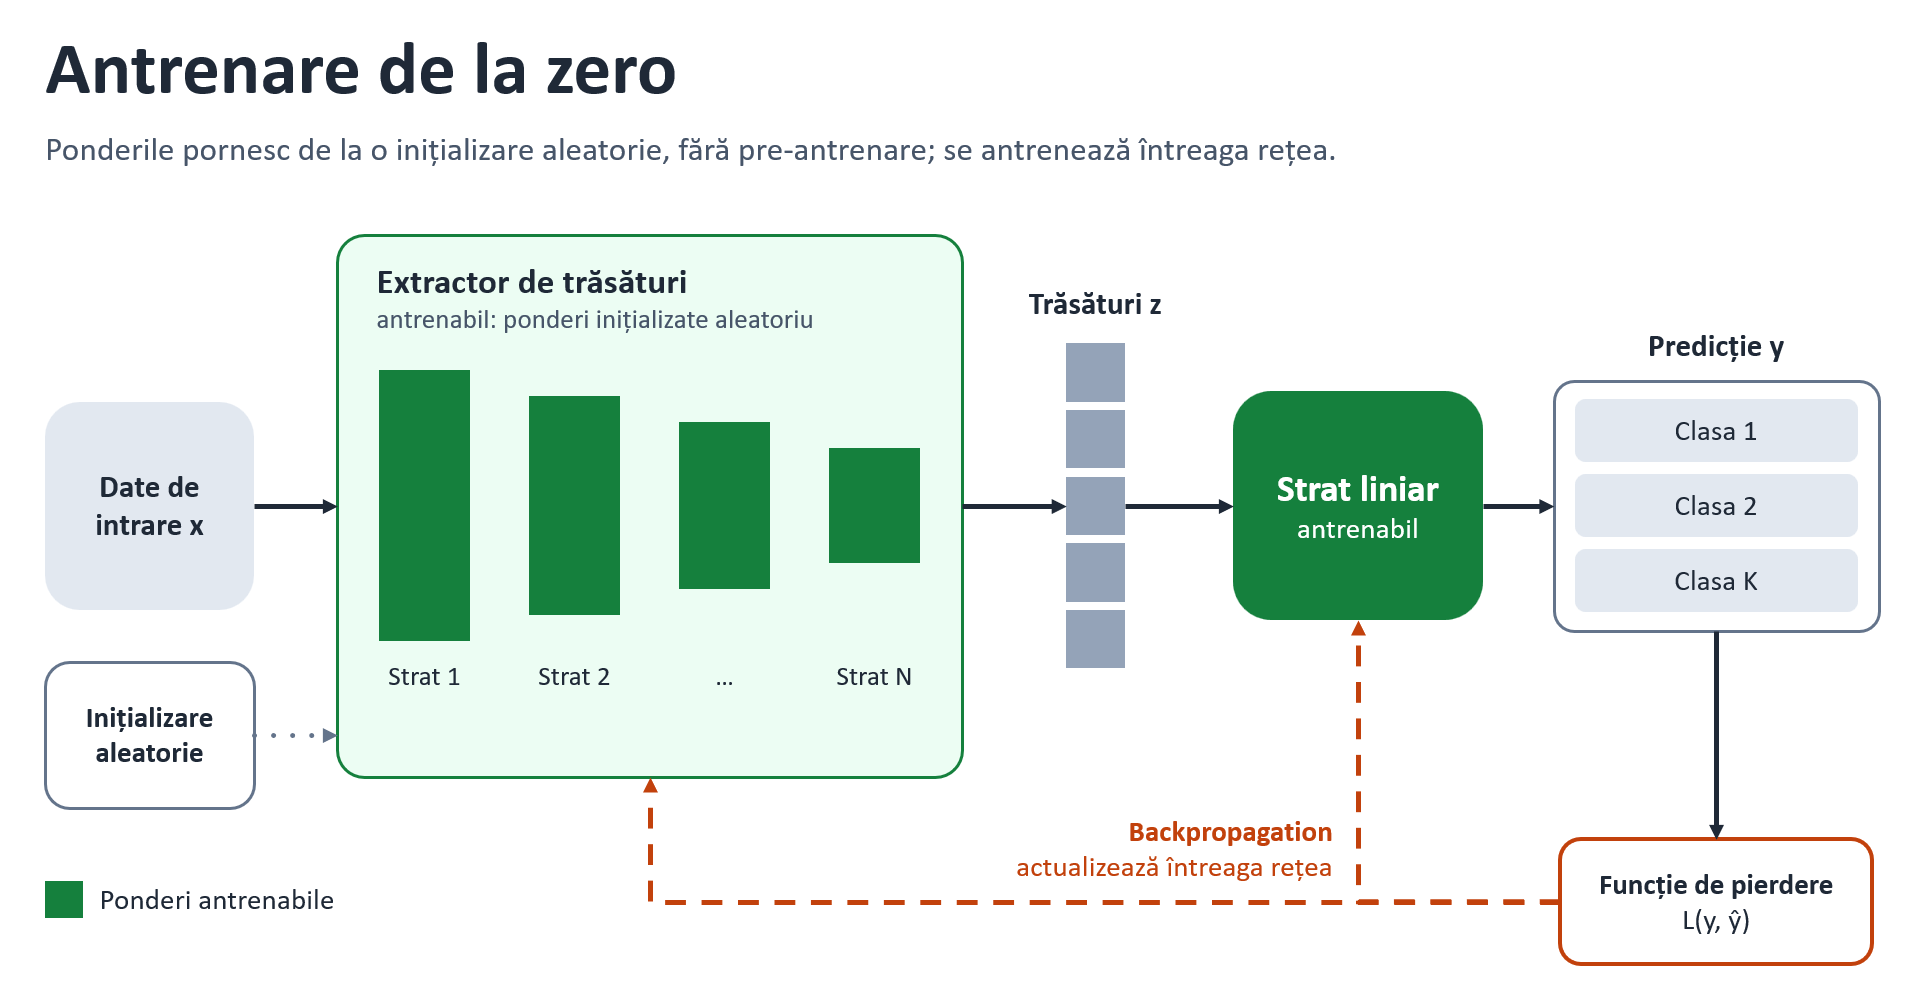


In [ ]:
set_seed(0)
scratch_model = build_classifier(use_se=False)
histories['De la 0'] = load_checkpoint(scratch_model, 'scratch')
if histories['De la 0'] is None:
    histories['De la 0'] = train_classifier(scratch_model, train_loader, valid_loader, epochs=EPOCHS['scratch'],
                                            lr_backbone=0.1, lr_head=0.1, desc='de la 0')
    save_checkpoint(scratch_model, 'scratch', histories['De la 0'])
record_results('De la 0', scratch_model)

## 5. Experimentul 2: pre-antrenare pe ImageNet + finetune
**Transfer learning:** trasaturile invatate de o retea pe o problema mare si variata sunt utile si pentru alte probleme. Straturile de inceput detecteaza muchii, culori si texturi, care sunt aceleasi in orice imagine naturala. Straturile adanci detecteaza parti de obiecte (ochi, roti, blana), care se refolosesc intre clase. Pornind de la astfel de ponderi, reteaua nu mai trebuie sa invete aceste trasaturi din cele 4.500 de imagini, ci doar sa le adapteze.

Ponderile de pornire sunt cele publicate in `torchvision` (ResNet-18, ImageNet-1k, 1,28 milioane de imagini, 1000 de clase). Acelasi mecanism functioneaza si cu ponderi pre-antrenate de voi pe alta baza de date: e suficient sa salvati `state_dict()` dupa antrenare si sa le incarcati aici in locul celor de pe ImageNet.

Folosim reteaua pre-antrenata in trei moduri, de la cel mai simplu la cel mai complet:
1. **Fara nicio antrenare (off-the-shelf):** folosim extractorul ImageNet direct pentru retrieval. Nu avem nevoie de etichete STL-10 si nici macar de un clasificator, pentru ca apelam doar `extract_features`.
2. **Linear probe:** inghetam extractorul si antrenam doar stratul liniar. Acuratetea obtinuta masoara cat de bine separa trasaturile pre-antrenate clasele STL-10. **Embedding-urile nu se schimba**, deci metricile de retrieval vor fi identice cu cele de la punctul 1. Doar acuratetea de clasificare se imbunatateste.
3. **Finetune complet:** pornim de la extractorul ImageNet si de la head-ul antrenat la pasul 2, apoi antrenam toata reteaua.


Ratele de invatare:
- linear probe: 0.01. Trasaturile ImageNet iesite din global average pooling au valori mari (norma vectorului este de ordinul zecilor), deci si gradientii stratului liniar sunt mari. Cu 0.1, functia de pierdere sare la valori de ordinul 10-15 in primele iteratii, desi in final converge;
- finetune: 0.003 pentru extractor si 0.01 pentru head. Rata extractorului este de aproximativ 30 de ori mai mica decat la antrenarea de la 0, pentru ca vrem doar sa ajustam fin ponderile, nu sa le inlocuim.
- ambele etape folosesc mult mai putine epoci decat antrenarea de la 0 (10 + 20), pentru ca pornesc de la un punct deja foarte bun.

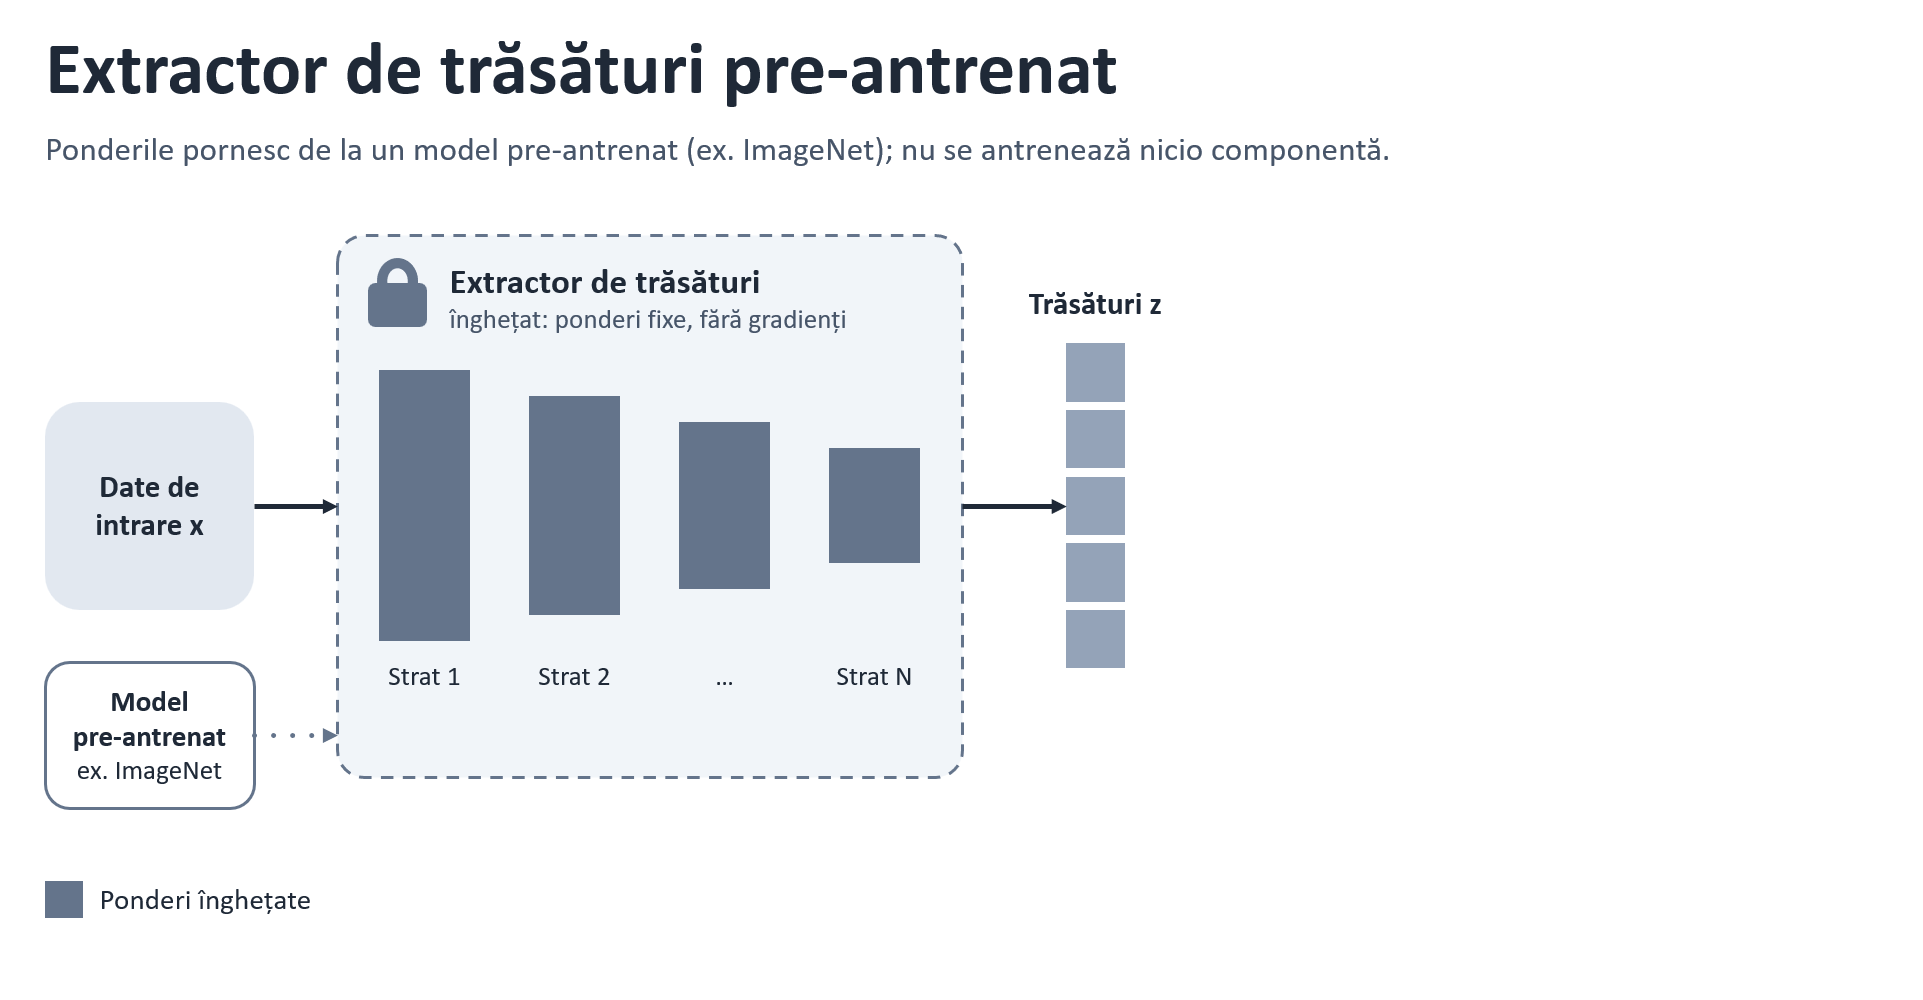

In [ ]:
# Off-the-shelf: folosim modelul pre-antrenat pe ImageNet
set_seed(0)
imagenet_model = build_classifier(use_se=False)
load_imagenet_backbone(imagenet_model)
record_results('ImageNet, fara antrenare', imagenet_model, has_trained_head=False)

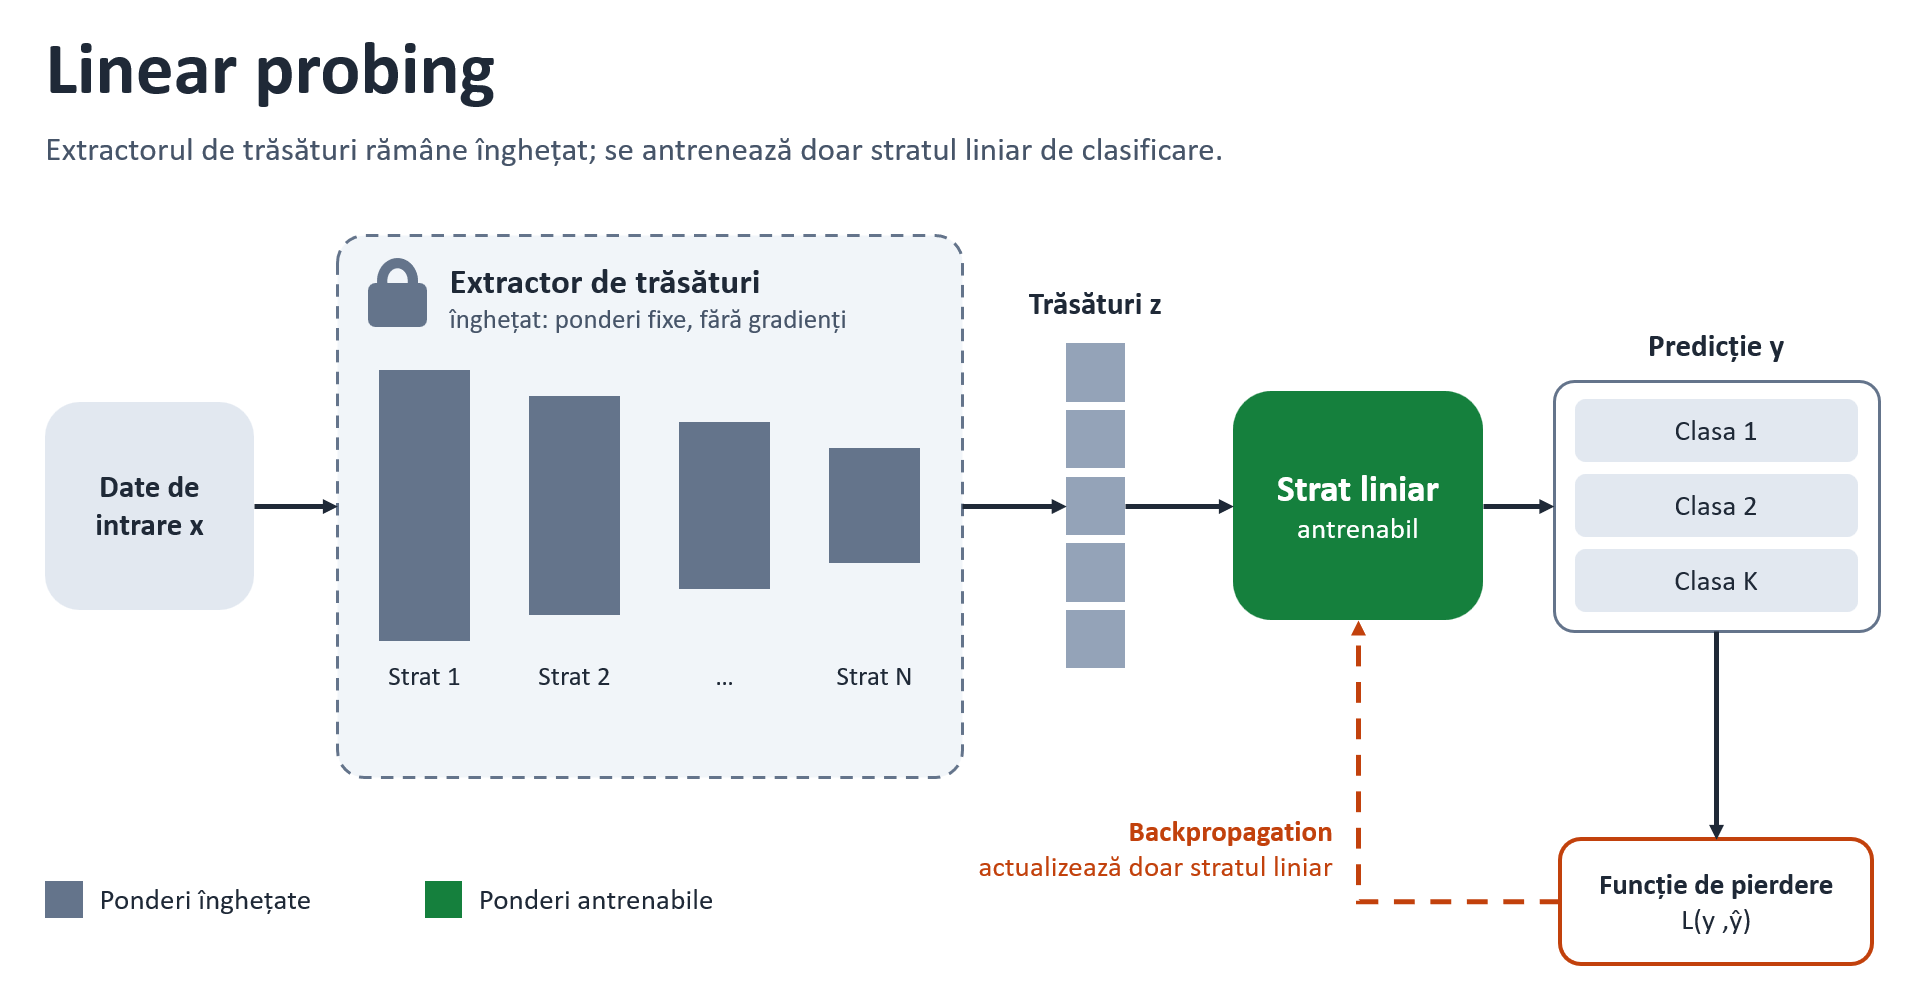

In [ ]:
# Linear probing: doar stratul liniar se antreneaza
histories['ImageNet + linear probe'] = load_checkpoint(imagenet_model, 'imagenet_linear_probe')
if histories['ImageNet + linear probe'] is None:
    histories['ImageNet + linear probe'] = train_classifier(imagenet_model, train_loader, valid_loader, epochs=EPOCHS['linear_probe'],
                                                            lr_backbone=0.0, lr_head=0.01, freeze_backbone=True, desc='linear probe')
    save_checkpoint(imagenet_model, 'imagenet_linear_probe', histories['ImageNet + linear probe'])
record_results('ImageNet + linear probe', imagenet_model)

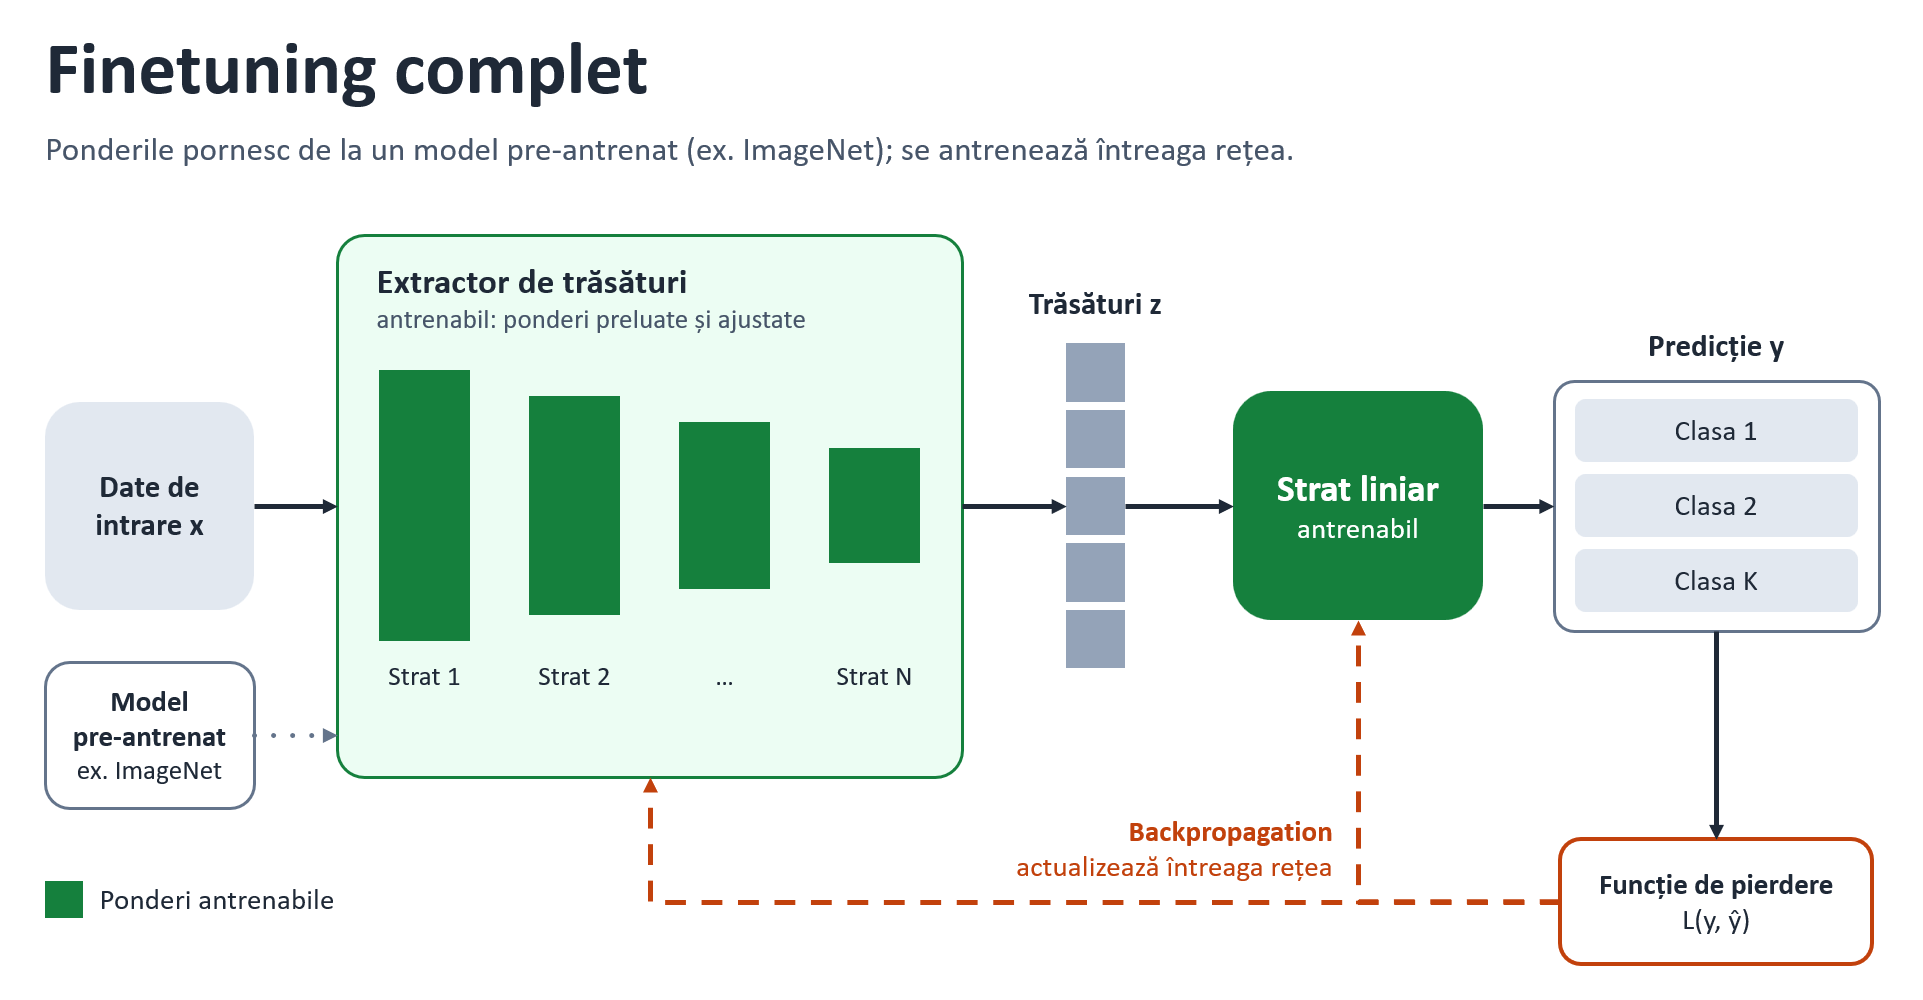

In [ ]:
# Finetune complet, pornind de la extractorul ImageNet si de la capul antrenat prin linear probe
histories['ImageNet + finetune'] = load_checkpoint(imagenet_model, 'imagenet_finetune')
if histories['ImageNet + finetune'] is None:
    histories['ImageNet + finetune'] = train_classifier(imagenet_model, train_loader, valid_loader, epochs=EPOCHS['finetune'],
                                                        lr_backbone=0.003, lr_head=0.01, desc='finetune')
    save_checkpoint(imagenet_model, 'imagenet_finetune', histories['ImageNet + finetune'])
record_results('ImageNet + finetune', imagenet_model)

## 6. Experimentul 3: Squeeze-and-Excitation
Antrenam SE-ResNet-18 de la 0, cu acelasi setup (hiperparametri, initializare, numar de epoci) ca ResNet-18 din experimentul 1. Singura diferenta este prezenta blocurilor SE, deci orice diferenta de rezultat li se poate atribui.

Varianta pre-antrenata nu poate fi folosita pentru comparatie, deoarece ponderile ImageNet din torchvision nu contin straturi SE. Adaugarea SE ar perturba trasaturile pre-antrenate. Comparatia ar masura atunci si efectul acestei perturbari, nu doar pe cel al mecanismului de atentie.

In [ ]:
set_seed(0)
se_model = build_classifier(use_se=True)
histories['SE, de la 0'] = load_checkpoint(se_model, 'se_scratch')
if histories['SE, de la 0'] is None:
    histories['SE, de la 0'] = train_classifier(se_model, train_loader, valid_loader, epochs=EPOCHS['scratch'],
                                                lr_backbone=0.1, lr_head=0.1, desc='SE de la 0')
    save_checkpoint(se_model, 'se_scratch', histories['SE, de la 0'])
record_results('SE, de la 0', se_model)

print('\nParametri: ResNet-18 = {:,} | SE-ResNet-18 = {:,} (+{:.2f} %)'.format(
    count_params(scratch_model), count_params(se_model), 100 * (count_params(se_model) / count_params(scratch_model) - 1)))

## 7. Compararea sistemelor de retrieval

### 7.1 Tabelul rezultatelor
- **Acc** este acuratetea de clasificare pe `test`. Lipseste pentru modelele fara classification head.
- **P@1, P@5, P@10, mAP** sunt metricile de retrieval din sectiunea 3.2.

Varianta "linear probe" are aceleasi metrici de retrieval ca varianta "fara antrenare". Antrenarea head-ului nu schimba extractorul, deci nici embedding-urile.

In [ ]:
columns = ['Acc', 'P@1', 'P@5', 'P@10', 'mAP']
print('{:<26}'.format('Model') + ''.join('{:>9}'.format(c) for c in columns))
print('-' * (26 + 9 * len(columns)))
for name, metrics in results.items():
    print('{:<26}'.format(name) + ''.join('{:>9}'.format('-' if math.isnan(metrics[c]) else '{:.2f}'.format(metrics[c])) for c in columns))

# Evolutia acuratetii pe validare in timpul antrenarii
fig, ax = plt.subplots(figsize=(10, 4.5))
for name, history in histories.items():
    if 'linear probe' not in name:
        ax.plot(range(1, len(history) + 1), history, label=name)
ax.set_xlabel('epoca')
ax.set_ylabel('acuratete pe validare (%)')
ax.set_title('Convergenta pe validare')
ax.grid(alpha=0.3)
ax.legend()
plt.show()

### 7.2 Exemple de cautari
Pentru cateva interogari alese aleator din `test` afisam primele 8 rezultate intoarse de fiecare model. Chenarul verde marcheaza un rezultat din aceeasi clasa ca interogarea, iar chenarul rosu unul gresit.

Urmariti si ce fel de greseli face fiecare model. Un model slab intoarce imagini cu aceleasi culori sau acelasi fundal (cer albastru pentru avion, dar si pentru pasare), adica se bazeaza pe trasaturi de nivel jos. Un model bun greseste mai ales intre clase semantic apropiate (pisica / caine, masina / camion).

In [ ]:
def add_border(image, color, width=4):
    # image: 3 x H x W in [0, 1]; color: (r, g, b)
    framed = torch.tensor(color, dtype=image.dtype).view(3, 1, 1).expand(3, image.shape[1] + 2 * width, image.shape[2] + 2 * width).clone()
    framed[:, width:-width, width:-width] = image
    return framed


def show_retrievals(model_names, query_indices, top_k=8):
    labels = y_test.to(device)
    for q in query_indices:
        fig, axes = plt.subplots(len(model_names), top_k + 1, figsize=(1.6 * (top_k + 1), 1.9 * len(model_names)))
        for row, name in enumerate(model_names):
            feats = embeddings[name]
            sims = feats @ feats[q]
            sims[q] = -float('inf')
            top = sims.topk(top_k).indices.tolist()
            query = add_border(x_test[q].float() / 255, (0.2, 0.4, 1.0))
            axes[row, 0].imshow(query.permute(1, 2, 0).numpy())
            axes[row, 0].set_title('query: ' + CLASSES[y_test[q]], fontsize=9)
            axes[row, 0].set_ylabel(name, fontsize=9)
            for col, idx in enumerate(top, start=1):
                ok = labels[idx] == labels[q]
                img = add_border(x_test[idx].float() / 255, (0.1, 0.75, 0.1) if ok else (0.9, 0.1, 0.1))
                axes[row, col].imshow(img.permute(1, 2, 0).numpy())
                axes[row, col].set_title('{:.2f}'.format(sims[idx].item()), fontsize=8)  # similaritatea cosinus
            for ax in axes[row]:
                ax.set_xticks([])
                ax.set_yticks([])
                for spine in ax.spines.values():
                    spine.set_visible(False)
        plt.tight_layout()
        plt.show()


compared_models = ['De la 0', 'SE, de la 0', 'ImageNet, fara antrenare', 'ImageNet + finetune']
show_retrievals(compared_models, query_indices=np.random.default_rng(5).choice(len(x_test), 4, replace=False).tolist())

### 7.3 Structura spatiului de trasaturi (t-SNE)
t-SNE este o metoda de proiectare a embedding-urilor dintr-un spatiu multi-dimensional intr-unul bidimensional. Astfel, el preia trasaturile de dimensiune 512 si le transpune in 2D, incercand sa pastreze vecinatatile: puncte apropiate in 2D sunt apropiate si in spatiul original. Folosim 2.000 de imagini de test, colorate dupa clasa. Retrieval-ul functioneaza bine exact atunci cand clasele formeaza grupuri compacte si separate: vecinii cei mai apropiati ai unei interogari sunt atunci din aceeasi clasa.

t-SNE pastreaza vecinatatile locale, dar nu si distantele mari. Faptul ca doua grupuri sunt departe unul de altul in grafic nu inseamna neaparat ca sunt departe si in spatiul original.

In [ ]:
from sklearn.manifold import TSNE

colors = plt.cm.tab10(np.arange(NUM_CLASSES))
subset = torch.from_numpy(np.random.default_rng(6).choice(len(x_test), 2000, replace=False))
fig, axes = plt.subplots(1, len(compared_models), figsize=(5.5 * len(compared_models), 5.5))
for ax, name in zip(axes, compared_models):
    points = TSNE(n_components=2, perplexity=30, init='pca', random_state=0).fit_transform(embeddings[name][subset].cpu().numpy())
    for c in range(NUM_CLASSES):
        mask = y_test[subset].numpy() == c
        ax.scatter(points[mask, 0], points[mask, 1], s=4, color=colors[c], label=CLASSES[c])
    ax.set_title('{}\nmAP = {:.1f} %'.format(name, results[name]['mAP']))
    ax.set_xticks([])
    ax.set_yticks([])
axes[0].legend(markerscale=4, fontsize=8, loc='lower left')
plt.tight_layout()
plt.show()

# #TODO:
1. Implementati partile marcate cu `TODO` din sectiunea 2: `SEBlock`, `BasicBlock.forward()` si clasa `ResNet18`. Rulati verificarea din sectiunea 2.6 inainte de orice antrenare.
2. Comparati rezultatele modurilor diferite de antrenare studiate.
3. De ce are extractorul ImageNet neantrenat un P@1 mare, dar un mAP mic? Ce ar trebui schimbat in antrenare pentru a optimiza direct mAP-ul?
4. Daca aveti la dispozitie 10 ori mai multe imagini etichetate, ce se intampla cu diferenta dintre antrenarea de la 0 si finetune? Dar daca aveti de 10 ori mai putine?
5. De ce nu este corect sa comparam SE-ResNet cu ResNet pornind de la ponderi ImageNet doar pentru ResNet?
6. In ce situatii practice ar fi preferabil retrieval-ul (k-NN pe embedding-uri) unui clasificator? Ce se intampla cand apare o clasa noua?
7. De ce este util sa folosim linear probing inainte de fine-tuning?